# 33장 · LangChain 검색 도구와 ToolMessage

검색 함수를 도구로 등록하면 모델이 정해진 인자 형식으로 검색을 요청할 수 있습니다. ToolMessage에는 어느 요청의 결과인지 나타내는 ID가 들어갑니다.

모델이 ‘도서관 자료를 찾아 달라’고 요청해도 검색은 아직 실행되지 않았습니다. 도구 요청의 이름과 인자를 읽고, 검색을 실행한 뒤 요청 ID가 붙은 결과를 돌려보냅니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 langchain-core 1.6.12, pydantic 2.14.1입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 도구 인자 스키마와 호출 요청

같은 retrieve를 수업용 검색 도구로 감쌉니다. 이름과 인자 규칙은 모델이 검색 요청을 작성할 때 읽습니다. 이 노트북에서는 모델이 보낼 법한 요청 한 건을 직접 만들어 네트워크 없이 실제 LangChain 도구에 전달합니다.


### 셀 01 · 도구 인자 스키마와 @tool

자료와 검색 함수는 30장과 같습니다. 맨 아래 search_documents의 이름과 k 인자 규칙만 찾아보세요.


In [1]:
records = [{'id': 'library-1',
  'text': '도서 대출 기간은 14일입니다.',
  'source': '가상 도서관 이용 안내',
  'page': 1},
 {'id': 'library-2',
  'text': '도서관은 월요일에 휴관합니다.',
  'source': '가상 도서관 이용 안내',
  'page': 2},
 {'id': 'library-3',
  'text': '무인 반납함은 24시간 이용할 수 있습니다.',
  'source': '가상 도서관 이용 안내',
  'page': 3}]
terms = ("대출", "휴관", "반납")

def retrieve(question, k=1):
    query = [int(term in question) for term in terms]
    if not any(query):
        return []
    def distance(row):
        vector = [int(term in row["text"]) for term in terms]
        return sum((a-b)**2 for a, b in zip(query, vector)), row["id"]
    return sorted(records, key=distance)[:k]

from langchain_core.tools import tool
from langchain_core.messages import AIMessage
from pydantic import BaseModel, ConfigDict, StrictInt, StrictStr, Field

class SearchArgs(BaseModel):
    model_config = ConfigDict(extra="forbid")
    question: StrictStr
    k: StrictInt = Field(default=2, ge=1)

@tool("search_documents", args_schema=SearchArgs, response_format="content_and_artifact")
def search_documents(question: str, k: int = 2):
    """가상 도서관의 대출·휴관·반납 안내를 찾습니다."""
    if not question.strip():
        raise ValueError("질문을 입력하세요.")
    found = retrieve(question, k)
    return "\n".join(row["text"] for row in found), found

print(search_documents.name)

search_documents


등록된 이름은 search_documents입니다. 이 이름을 찍은 것만으로는 검색을 한 번도 실행하지 않았습니다.


### 필수 검색에서 호출 가능한 도구로

<p>앞 장의 검색 함수는 고정된 순서에서 실행됐습니다. 여기서는 같은 retrieve를 이름이 있는 도구로 감쌉니다. 등록하고 요청을 만드는 셀까지는 검색 결과가 아직 없습니다.</p>


### 도구 이름·설명·인자 스키마

<p>도구 명세에는 이름, 사용할 상황을 알려 주는 설명, 받을 인자의 구조가 들어갑니다. 이름 search_documents는 실행할 함수를 찾는 기준입니다. 설명은 가상 도서관의 대출·휴관·반납 자료를 검색한다는 범위를 알립니다. 짧아도 자료의 범위와 반환 목적이 드러나야 합니다.</p>

<p>question은 무엇을 찾을지, k는 문서를 최대 몇 개 받을지를 나타냅니다. 기본값 2는 생략할 수 있다는 뜻이며 반드시 두 문서가 나온다는 뜻은 아닙니다. Tool의 설명이 있어도 실제 모델이 항상 필요한 검색을 선택한다고 보장할 수는 없습니다.</p>

<table><caption>입력 규칙을 예상해 보기</caption><thead><tr><th scope="col">입력</th><th scope="col">처리</th><th scope="col">이유</th></tr>
</thead><tbody><tr><td>question="대출 기간은?", k=1</td><td>검색 실행</td><td>문자열 질문과 양의 정수</td></tr>
<tr><td>question=" "</td><td>검색 전 거부</td><td>공백뿐인 질문</td></tr>
<tr><td>k=True 또는 k="2"</td><td>검색 전 거부</td><td>엄격한 정수 규칙</td></tr>
<tr><td>k=0 또는 extra=1</td><td>검색 전 거부</td><td>양수 조건 또는 모르는 인자</td></tr>
</tbody></table>

<p>BaseModel·Field·StrictInt는 이 장에서 제공하는 검사 코드입니다. 이름의 뜻과 입력 결과만 읽고 클래스 내부를 새로 구현할 필요는 없습니다. Python에서는 True가 정수처럼 쓰일 수 있으므로 엄격한 검사를 두어 기존 R1의 규칙을 유지합니다. 추가 인자를 거부하면 오타를 조용히 무시하지 않습니다.</p>


### content_and_artifact의 두 반환값

<p>도구 함수는 검색 문장들을 줄바꿈으로 이은 문자열과 원래 레코드 리스트를 쌍으로 돌려줍니다. 첫 값은 읽을 내용, 둘째 값은 id와 page까지 갖춘 구조화된 근거입니다.</p>


### AIMessage를 만들어도 검색은 아직 0회입니다

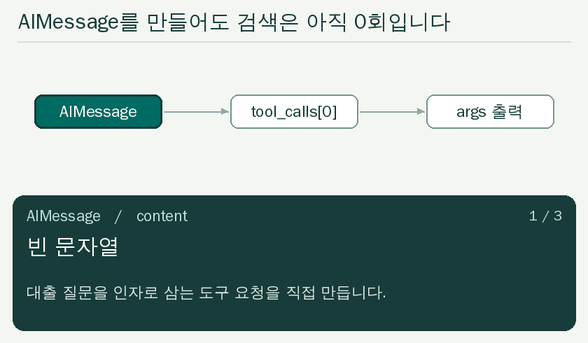

셀 02의 흐름은 요청을 만드는 데서 끝납니다. 모델 API나 retrieve를 호출하지 않고도 요청의 이름·인자·ID를 검사할 수 있습니다.


### 셀 02 · 도구 호출 메시지 구성

질문과 k가 담긴 도구 호출을 AIMessage에서 꺼내세요.


In [2]:
request = AIMessage(content='', tool_calls=[{'id': 'search-1', 'name': 'search_documents', 'args': {'question': '대출 기간은?', 'k': 1}, 'type': 'tool_call'}])
call = request.tool_calls[0]
print(call['args'])

{'question': '대출 기간은?', 'k': 1}


대출 질문과 검색 상한 1이 나옵니다. 이 시점에는 문서가 없습니다.


### AIMessage.tool_calls에서 요청 읽기

<p>이 예제는 AIMessage를 코드에서 직접 만듭니다. tool_calls[0]에는 도구 이름·인자·요청 ID가 들어 있습니다. args를 출력하는 줄까지 실행해도 search_documents의 본문은 호출되지 않습니다.</p>


## tool_call_id로 ToolMessage 연결

invoke에 인자만 넘길 때와 달리 호출 ID까지 포함한 요청을 건네면 ToolMessage에서 어느 요청의 결과인지 읽을 수 있습니다. 화면에는 실제 검색 자료를 싣고 메시지에는 다음 판단에 필요한 내용을 담습니다.

<!-- lesson-visual visual-send-back -->
**ToolMessage가 모델에게 돌아가는 길**

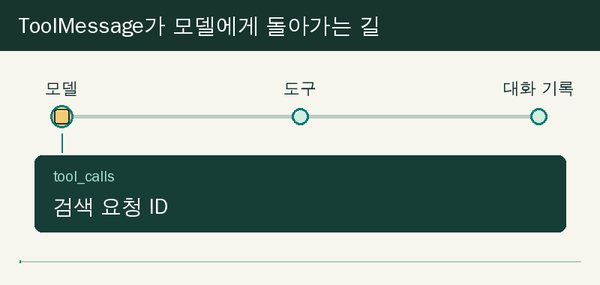

검색 도구의 출력에 원래 요청의 ID를 붙입니다. 모델은 tool_call_id로 어느 요청에서 온 결과인지 연결할 수 있습니다.
<!-- /lesson-visual visual-send-back -->


### 과제 03 · ToolMessage와 요청 ID

call을 도구로 실행한 뒤 tool_call_id와 첫 문서의 id를 표시하세요.

이 셀의 content에는 검색한 문서의 본문이 일반 문자열로 들어갑니다. artifact에는 id·text·source·page를 보관합니다. 참고 구현은 content를 JSON 문자열로 만들지만 여기서는 도서관 안내 문장을 그대로 읽으세요.


In [3]:
# call 전체를 search_documents.invoke에 넘기세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>reply = search_documents.invoke(call)
print(reply.tool_call_id, reply.artifact[0][&#x27;id&#x27;])</code></pre>
<p>실행 결과</p><pre><code>search-1 library-1</code></pre>
<p>search-1은 요청 식별자, library-1은 근거 문서 식별자입니다. 이 둘을 바꿔 쓰면 다음 판단에서 어떤 요청에 답이 왔는지 찾기 어렵습니다.</p>
</details>


### 요청 ID와 근거 문서 ID

<p>ToolMessage의 tool_call_id는 어떤 요청의 응답인지 식별합니다. artifact 안의 id는 어느 문서를 찾았는지 식별합니다. 요청이 search-1이고 문서가 library-1인 두 값은 용도가 다릅니다.</p>

<h3>요청을 보낸 뒤 학생 셀이 멈추는 위치</h3>

<p>셀 03은 ToolMessage에서 tool_call_id와 artifact의 첫 문서 ID를 읽습니다. 도구 결과를 LLM에 다시 보내거나 새 답을 생성하는 호출은 이 셀에 없습니다.</p>


### 호출 정보를 통째로 invoke()에 넘기는 이유

<p>call에는 type="tool_call"과 id가 들어 있습니다. call 전체를 넘기면 프레임워크가 도구 결과를 ToolMessage로 감싸고 요청의 ID를 연결합니다. args만 따로 출력한 직전 셀과 비교해 보세요.</p>


### 빈 결과를 돌려준 호출

<p>대출·휴관·반납이 없는 질문이면 이 검색 함수는 빈 리스트를 돌려줍니다. 그때도 도구를 호출했다면 요청 ID가 있는 결과를 받을 수 있습니다. 호출하기 전에는 결과 메시지 자체가 없습니다.</p>


### 잘못된 인자가 검색에 도달하기 전

<p>SearchArgs에서 k는 1 이상의 StrictInt입니다. 문자열 "1"이나 정수 0을 k로 넣으면 인자 검증에서 멈춥니다. 자료가 없어 빈 목록을 반환한 정상 검색과 발생 지점이 다릅니다.</p>


### 도구를 실제로 실행하면 두 종류의 ID가 만납니다

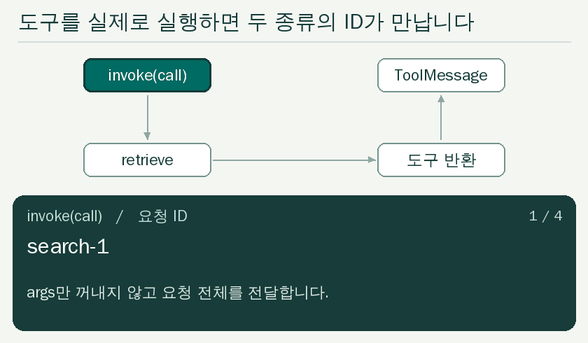

프레임워크가 요청의 id를 결과 메시지에 연결합니다. artifact 안의 문서 id는 검색 레코드로부터 옵니다.


## 돌아보기

도구 응답이 빈 목록이면 호출 자체는 끝난 상태입니다. 검색 호출을 건너뛴 경우와 구별할 수 있도록 요청 ID, 실행 여부, 자료 목록을 함께 읽으세요.

### 검색 요청과 결과의 한 차례 왕복

**사용자가 질문한다**　질문 문자열을 메시지로 보관합니다.

```
대출 기간은?
```

**검색을 요청한다**　아직 검색은 실행되지 않았습니다.

```
name=search_documents
id=search-1
args={question: 대출 기간은?, k: 1}
```

**같은 retrieve를 부른다**　실행 후 검증한 근거를 ToolMessage로 돌려줍니다.

```
tool_call_id=search-1
status=success
artifact=[library-1]
```

**결과를 읽고 검색 선택을 마친다**　이 fixture는 추가 도구를 요청하지 않습니다. A1 답변 생성은 별도 단계입니다.

```
tool_calls=[]
```
